Problem Statement
To design and implement a machine learning-based web application that predicts student academic performance using historical student data.
Imporment
it perdicts student performance in different activity also

In [2]:
#importing all the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import joblib

In [7]:
import os
os.path.exists(r"C:\Users\harik\ml.project\ml_model\data\raw\StudentsPerformance.csv")


True

In [8]:
#Reading csv file
df = pd.read_csv(r"C:\Users\harik\ml.project\ml_model\data\raw\StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [10]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [13]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [11]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [14]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [15]:
#Checking the duplicate data
df.duplicated().sum()

0

In [16]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Encode categorical columns
categorical_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,0,1,1,1,1,72,72,74
1,0,2,4,1,0,69,90,88
2,0,1,3,1,1,90,95,93
3,1,0,0,0,1,47,57,44
4,1,2,4,1,1,76,78,75


In [19]:
#define numerical and categorical columns
# Numerical columns
numeric_features = df.select_dtypes(exclude='object').columns.tolist()

# Categorical columns
categorical_features = df.select_dtypes(include='object').columns.tolist()

print(f"We have {len(numeric_features)} numerical features:")
print(numeric_features)

print(f"\nWe have {len(categorical_features)} categorical features:")
print(categorical_features)


We have 8 numerical features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

We have 0 categorical features:
[]


In [24]:
#adding colums
df['total_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
)
df['average_score'] = df['total_score'] / 3

df['result'] = df['average_score'].apply(
    lambda x: 'Pass' if x >= 40 else 'Fail'
)

df[['math score', 'reading score', 'writing score', 'total_score','average_score','result']].head()


,math score,reading score,writing score,total_score,average_score,result
0,72,72,74,218,72.666667,Pass
1,69,90,88,247,82.333333,Pass
2,90,95,93,278,92.666667,Pass
3,47,57,44,148,49.333333,Pass
4,76,78,75,229,76.333333,Pass


In [ ]:
df['high_performer'] = (df['average_score'] >= 75).astype(int)
df.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score,result,high_performer
0,0,1,1,1,1,72,72,74,218,72.666667,Pass,0
1,0,2,4,1,0,69,90,88,247,82.333333,Pass,1
2,0,1,3,1,1,90,95,93,278,92.666667,Pass,1
3,1,0,0,0,1,47,57,44,148,49.333333,Pass,0
4,1,2,4,1,1,76,78,75,229,76.333333,Pass,1
5,0,1,0,1,1,71,83,78,232,77.333333,Pass,1
6,0,1,4,1,0,88,95,92,275,91.666667,Pass,1
7,1,1,4,0,1,40,43,39,122,40.666667,Pass,0
8,1,3,2,0,0,64,64,67,195,65.000000,Pass,0
9,0,1,2,0,1,38,60,50,148,49.333333,Pass,0


Data Visualizations
visula
Data Visualizations for your Student Performance Prediction

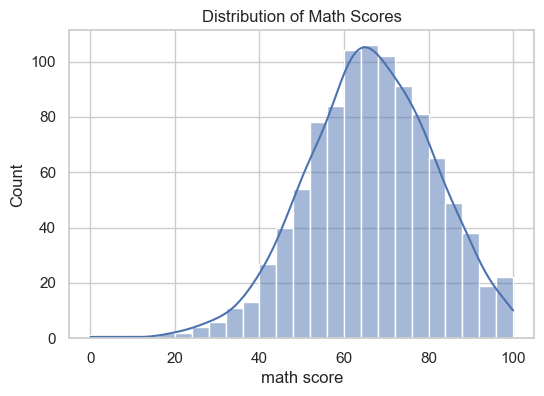

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
#Math Score Distribution
plt.figure(figsize=(6,4))
sns.histplot(df['math score'], kde=True)
plt.title("Distribution of Math Scores")
plt.show()


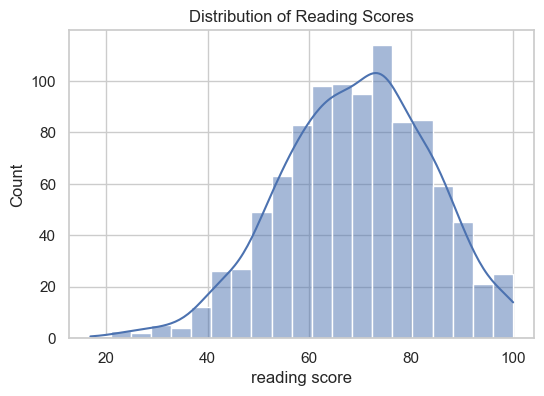

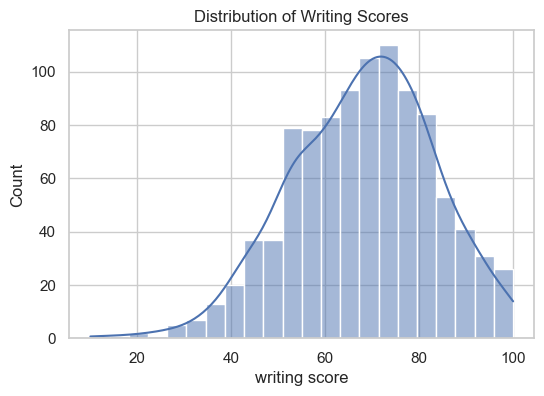

In [29]:
plt.figure(figsize=(6,4))
sns.histplot(df['reading score'], kde=True)
plt.title("Distribution of Reading Scores")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df['writing score'], kde=True)
plt.title("Distribution of Writing Scores")
plt.show()


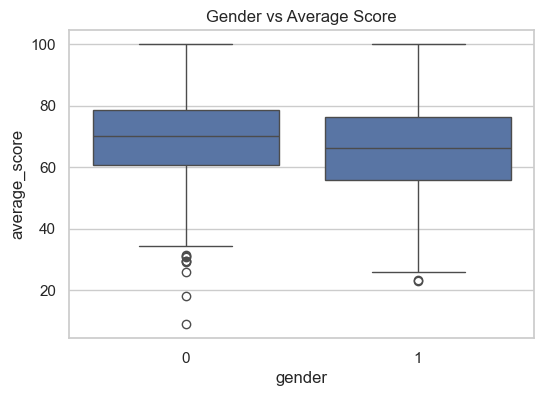

In [ ]:
#Gender vs Performance
#📊 Average Score by Gender
df['average_score'] = df['total_score'] / 3

plt.figure(figsize=(6,4))
sns.boxplot(x='gender', y='average_score', data=df)
plt.title("Gender vs Average Score")
plt.show()


In [31]:
# Features (X) and Target (y)
X = df.drop(['math score'], axis=1)  # All columns except math score
y = df['math score']                 # Column to predict

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1000, 11)
Target shape: (1000,)


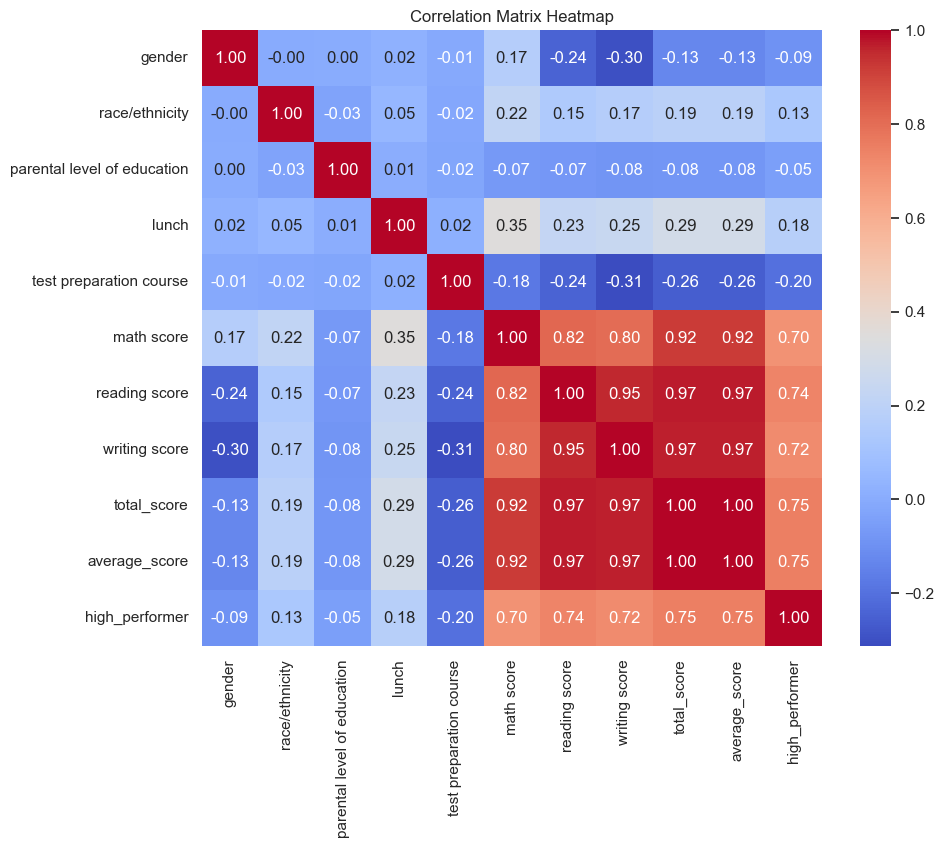

In [34]:
corr_matrix = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()


In [8]:
#adding colums
df['total_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
)
df['average_score'] = df['total_score'] / 3

df['result'] = df['average_score'].apply(
    lambda x: 'Pass' if x >= 40 else 'Fail'
)

df[['math score', 'reading score', 'writing score', 'total_score','average_score','result']].head()
df['high_performer'] = (df['average_score'] >= 75).astype(int)
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score,result,high_performer
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,Pass,0
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,Pass,1
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,Pass,1
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,Pass,0
4,male,group C,some college,standard,none,76,78,75,229,76.333333,Pass,1


In [9]:
import pandas as pd
reading_full = df[df['reading score'] == 100]['average_score'].count()
writing_full = df[df['writing score'] == 100]['average_score'].count()
math_full = df[df['math score'] == 100]['average_score'].count()

print(f"Number of students with full marks in Math: {math_full}")
print(f"Number of students with full marks in Reading: {reading_full}")
print(f"Number of students with full marks in Writing: {writing_full}")


Number of students with full marks in Math: 7
Number of students with full marks in Reading: 17
Number of students with full marks in Writing: 14


In [10]:
reading_less_20 = df[df['reading score'] < 20]['average_score'].count()
writing_less_20 = df[df['writing score'] < 20]['average_score'].count()
math_less_20 = df[df['math score'] < 20]['average_score'].count()
print(f"Number of students with less than 20 marks in Math: {math_less_20}")
print(f"Number of students with less than 20 marks in Reading: {reading_less_20}")
print(f"Number of students with less than 20 marks in Writing: {writing_less_20}")


Number of students with less than 20 marks in Math: 4
Number of students with less than 20 marks in Reading: 1
Number of students with less than 20 marks in Writing: 3


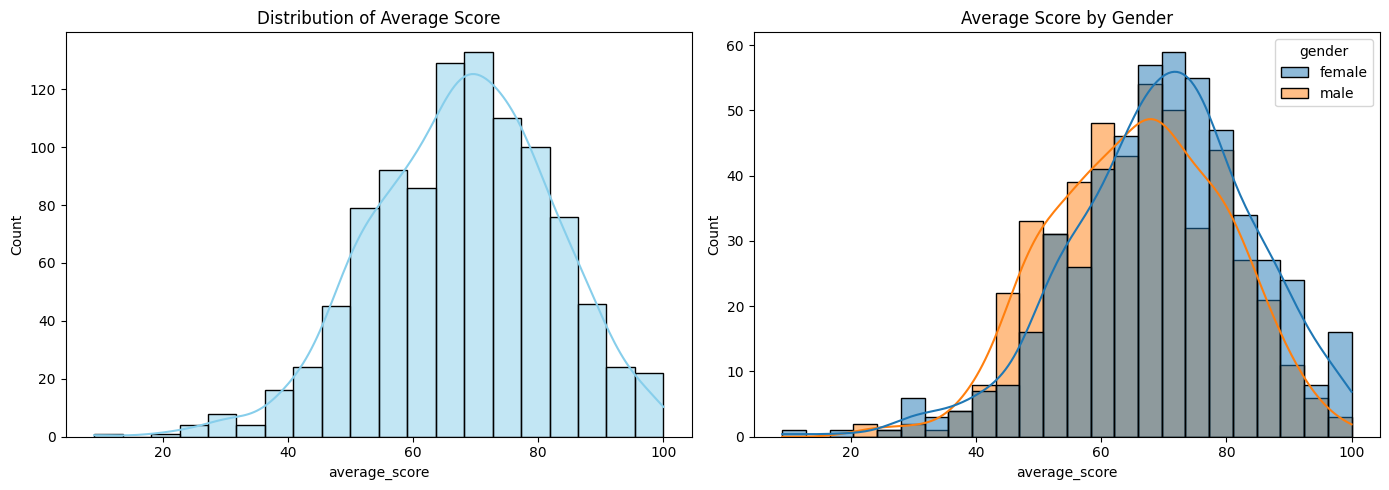

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram of average score
sns.histplot(
    data=df,
    x='average_score',
    bins=20,
    kde=True,
    ax=axs[0],
    color='skyblue'
)
axs[0].set_title("Distribution of Average Score")

# Plot 2: Histogram of average score by gender
sns.histplot(
    data=df,
    x='average_score',
    kde=True,
    hue='gender',
    ax=axs[1]
)
axs[1].set_title("Average Score by Gender")

plt.tight_layout()
plt.show()


Insights

In general parents education is not helping the students to perform well in exam

2nd plot shows that the parents with associate degree or mater's degree their male child tend to perform well in exam

3rd plot we can say that there's no effect of parents education on female child

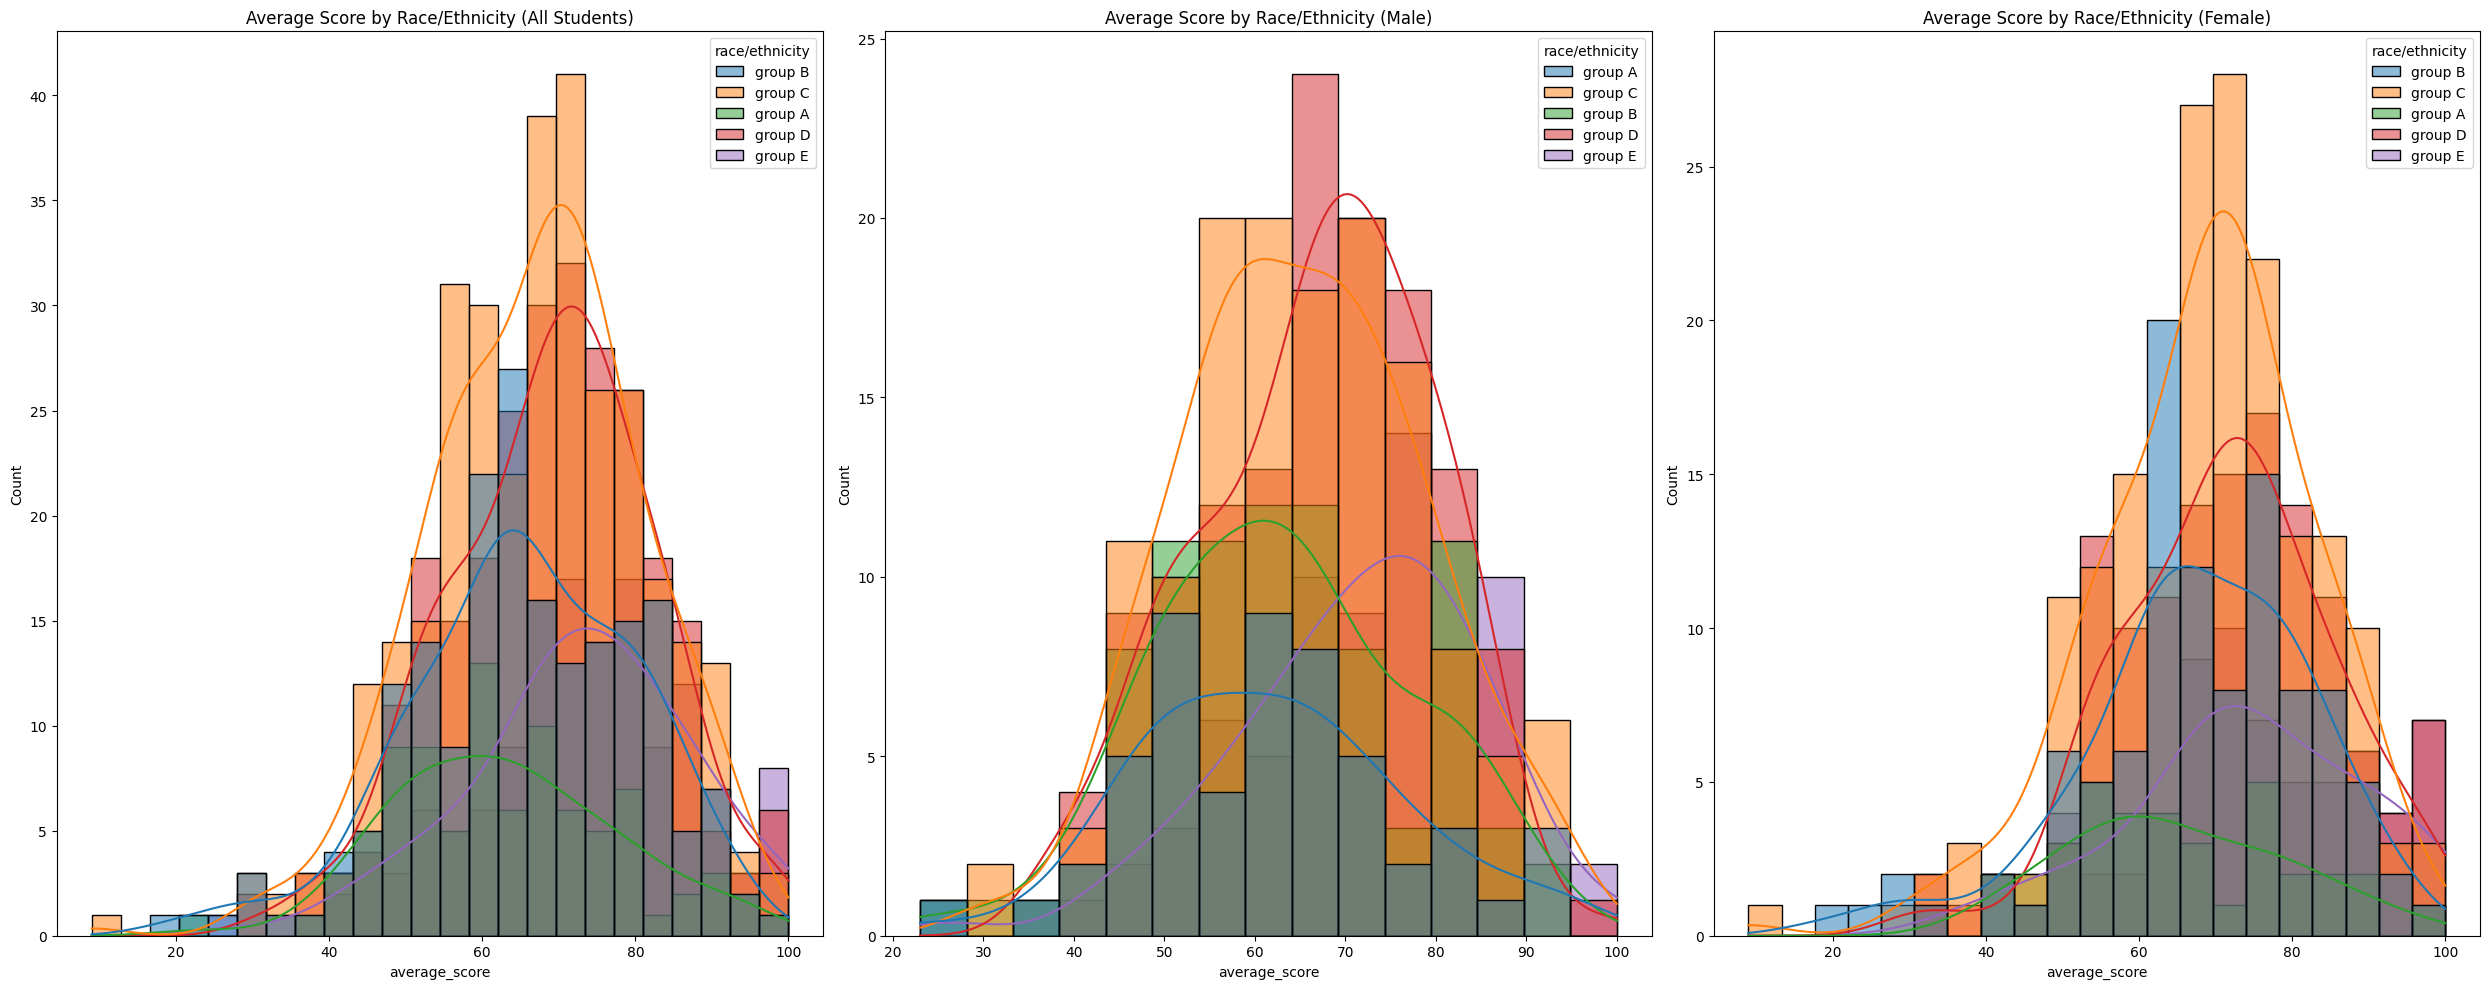

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create 1 row, 3 columns
plt.subplots(1, 3, figsize=(25, 10))

# Plot 1: All students
plt.subplot(131)
sns.histplot(
    data=df,
    x='average_score',
    kde=True,
    hue='race/ethnicity'
)
plt.title("Average Score by Race/Ethnicity (All Students)")

# Plot 2: Male students
plt.subplot(132)
sns.histplot(
    data=df[df['gender'] == 'male'],
    x='average_score',
    kde=True,
    hue='race/ethnicity'
)
plt.title("Average Score by Race/Ethnicity (Male)")

# Plot 3: Female students
plt.subplot(133)
sns.histplot(
    data=df[df['gender'] == 'female'],
    x='average_score',
    kde=True,
    hue='race/ethnicity'
)
plt.title("Average Score by Race/Ethnicity (Female)")

plt.tight_layout()
plt.show()


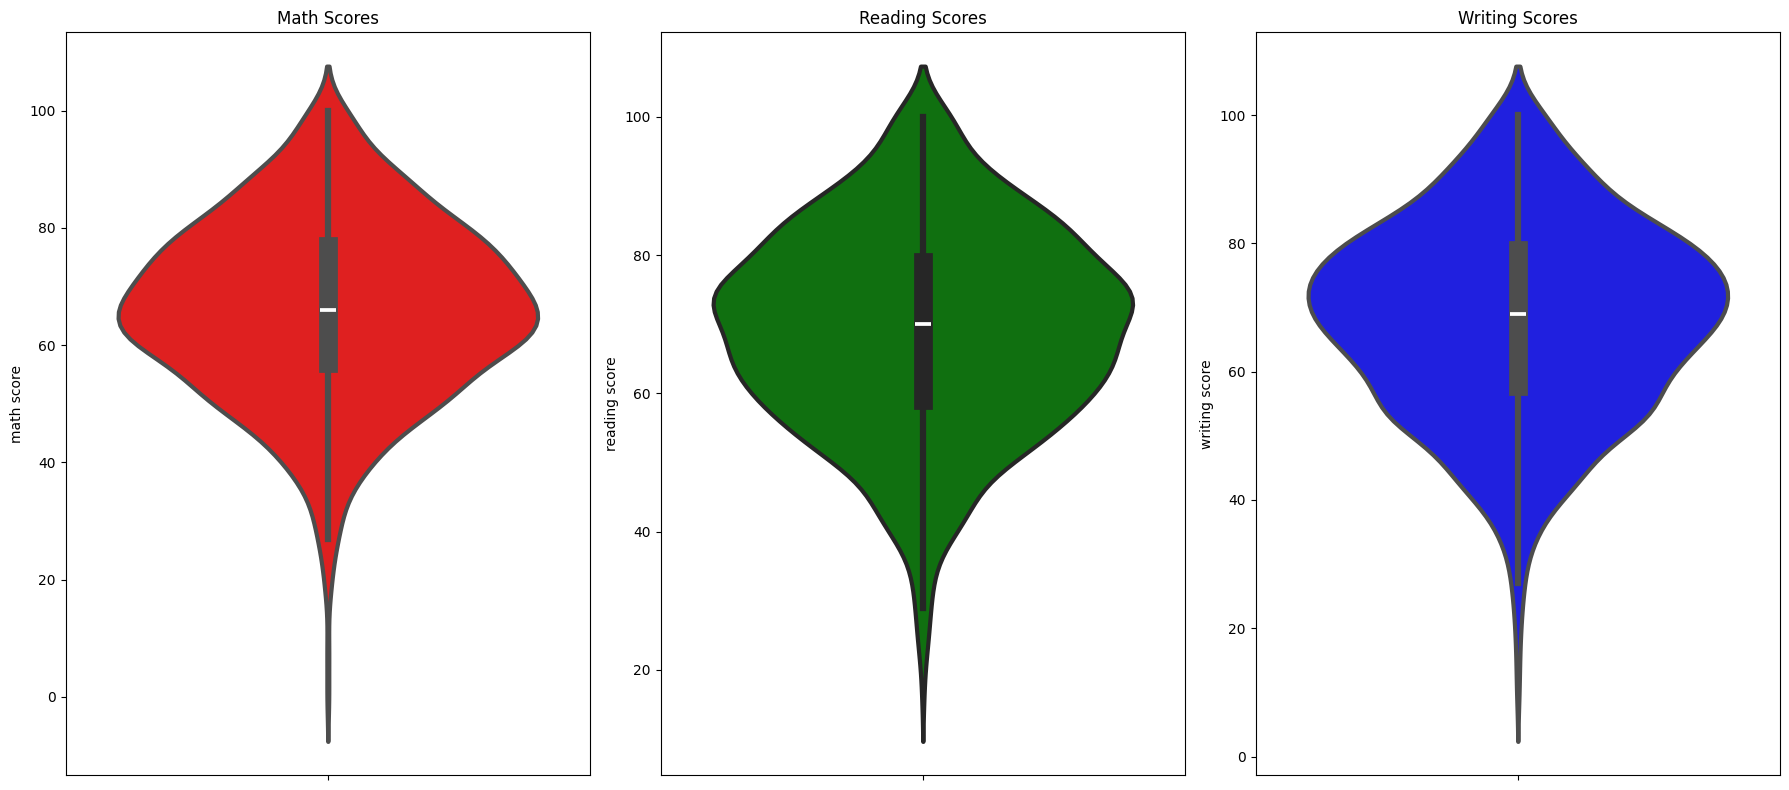

In [13]:
#Maximum Score Distribution (Violin Plots)

plt.figure(figsize=(18, 8))

# Math Score
plt.subplot(1, 3, 1)
plt.title('Math Scores')
sns.violinplot(data=df, y='math score', color='red', linewidth=3)

# Reading Score
plt.subplot(1, 3, 2)
plt.title('Reading Scores')
sns.violinplot(data=df, y='reading score', color='green', linewidth=3)

# Writing Score
plt.subplot(1, 3, 3)
plt.title('Writing Scores')
sns.violinplot(data=df, y='writing score', color='blue', linewidth=3)

plt.tight_layout()
plt.show()


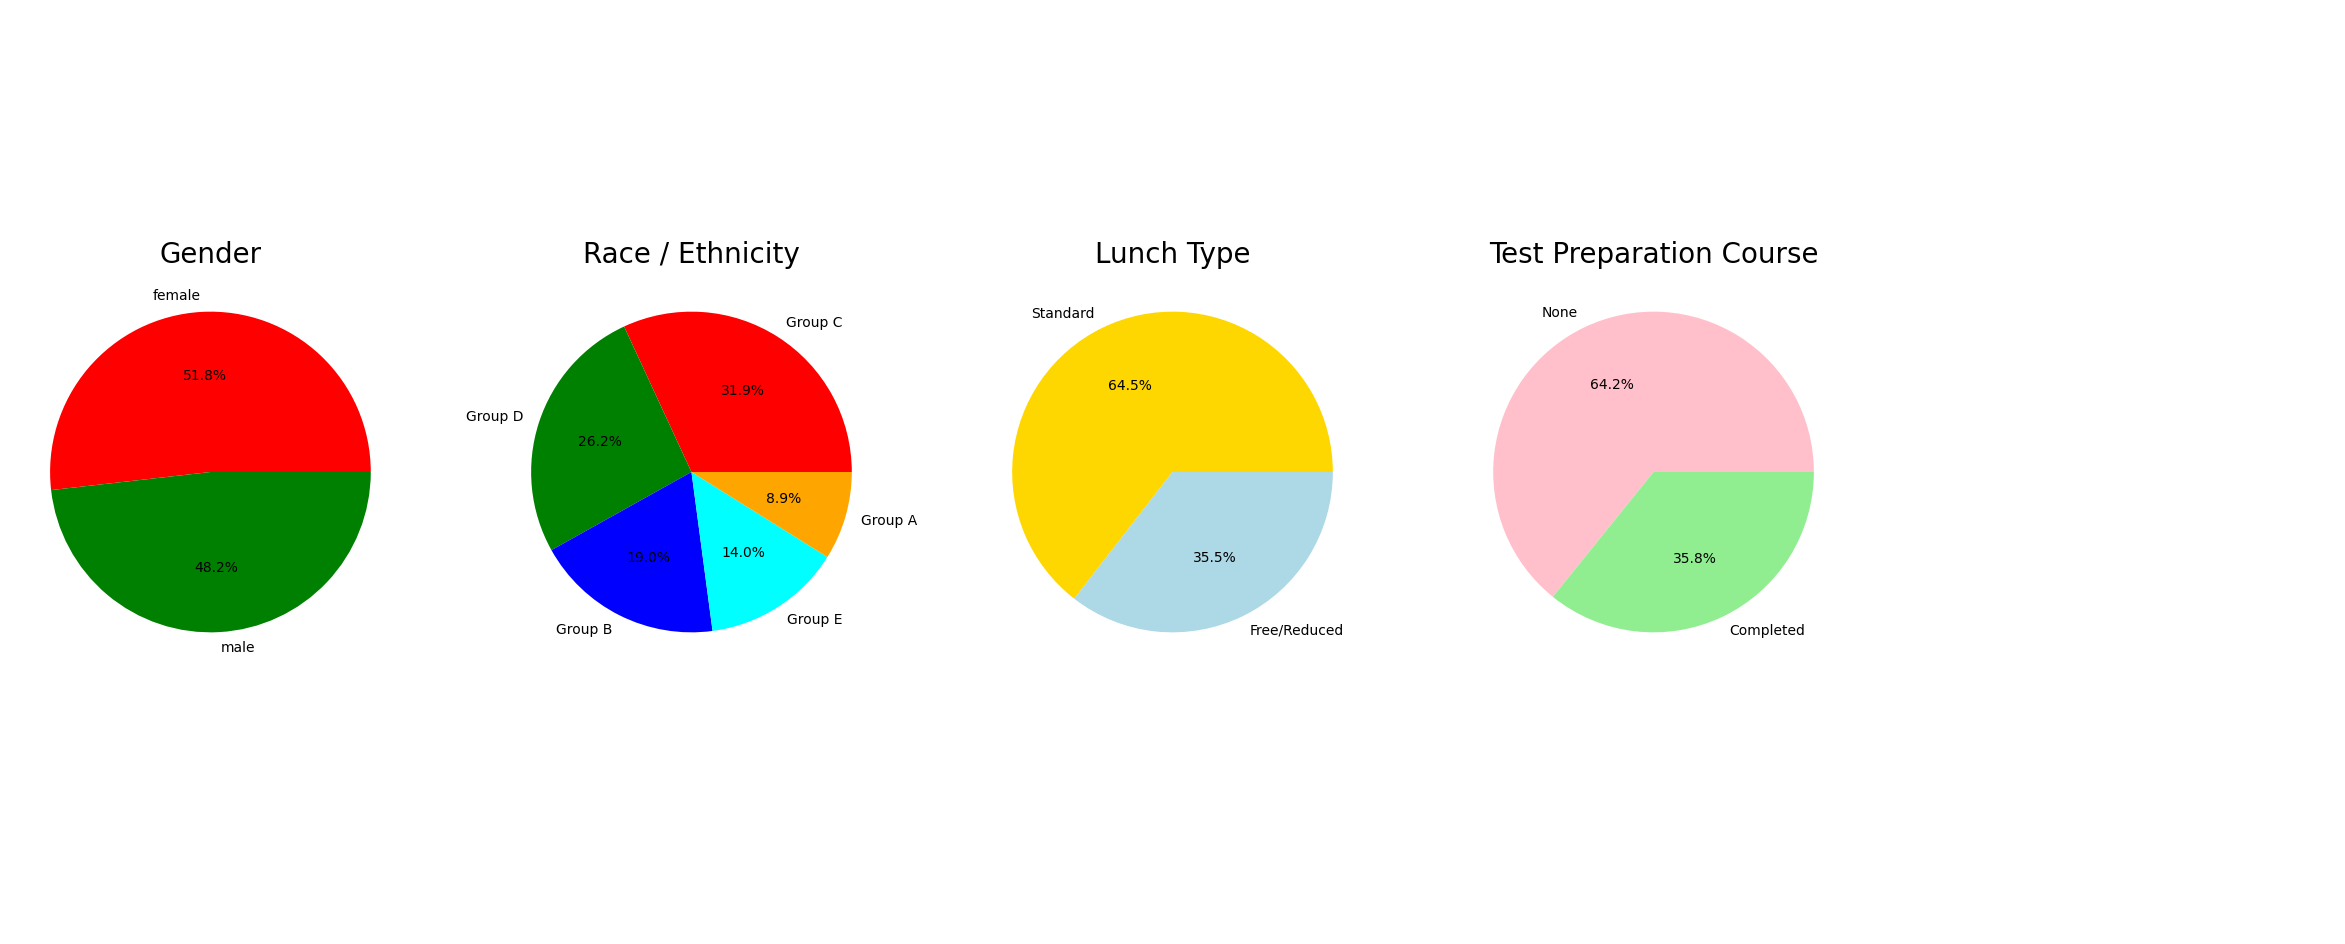

In [14]:
#Multivariate Analysis using Pie Charts
plt.rcParams['figure.figsize'] = (30, 12)
plt.subplot(1, 5, 1)
size = df['gender'].value_counts()
labels = ['female', 'male']
colors = ['red', 'green']
plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Gender', fontsize=20)
plt.axis('off')
plt.subplot(1, 5, 2)
size = df['race/ethnicity'].value_counts()
labels = ['Group C', 'Group D', 'Group B', 'Group E', 'Group A']
colors = ['red', 'green', 'blue', 'cyan', 'orange']
plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Race / Ethnicity', fontsize=20)
plt.axis('off')
plt.subplot(1, 5, 3)
size = df['lunch'].value_counts()
labels = ['Standard', 'Free/Reduced']
colors = ['gold', 'lightblue']
plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Lunch Type', fontsize=20)
plt.axis('off')
plt.subplot(1, 5, 4)
size = df['test preparation course'].value_counts()
labels = ['None', 'Completed']
colors = ['pink', 'lightgreen']
plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Test Preparation Course', fontsize=20)
plt.axis('off')
plt.subplot(1, 5, 5)
plt.axis('off')

plt.show()


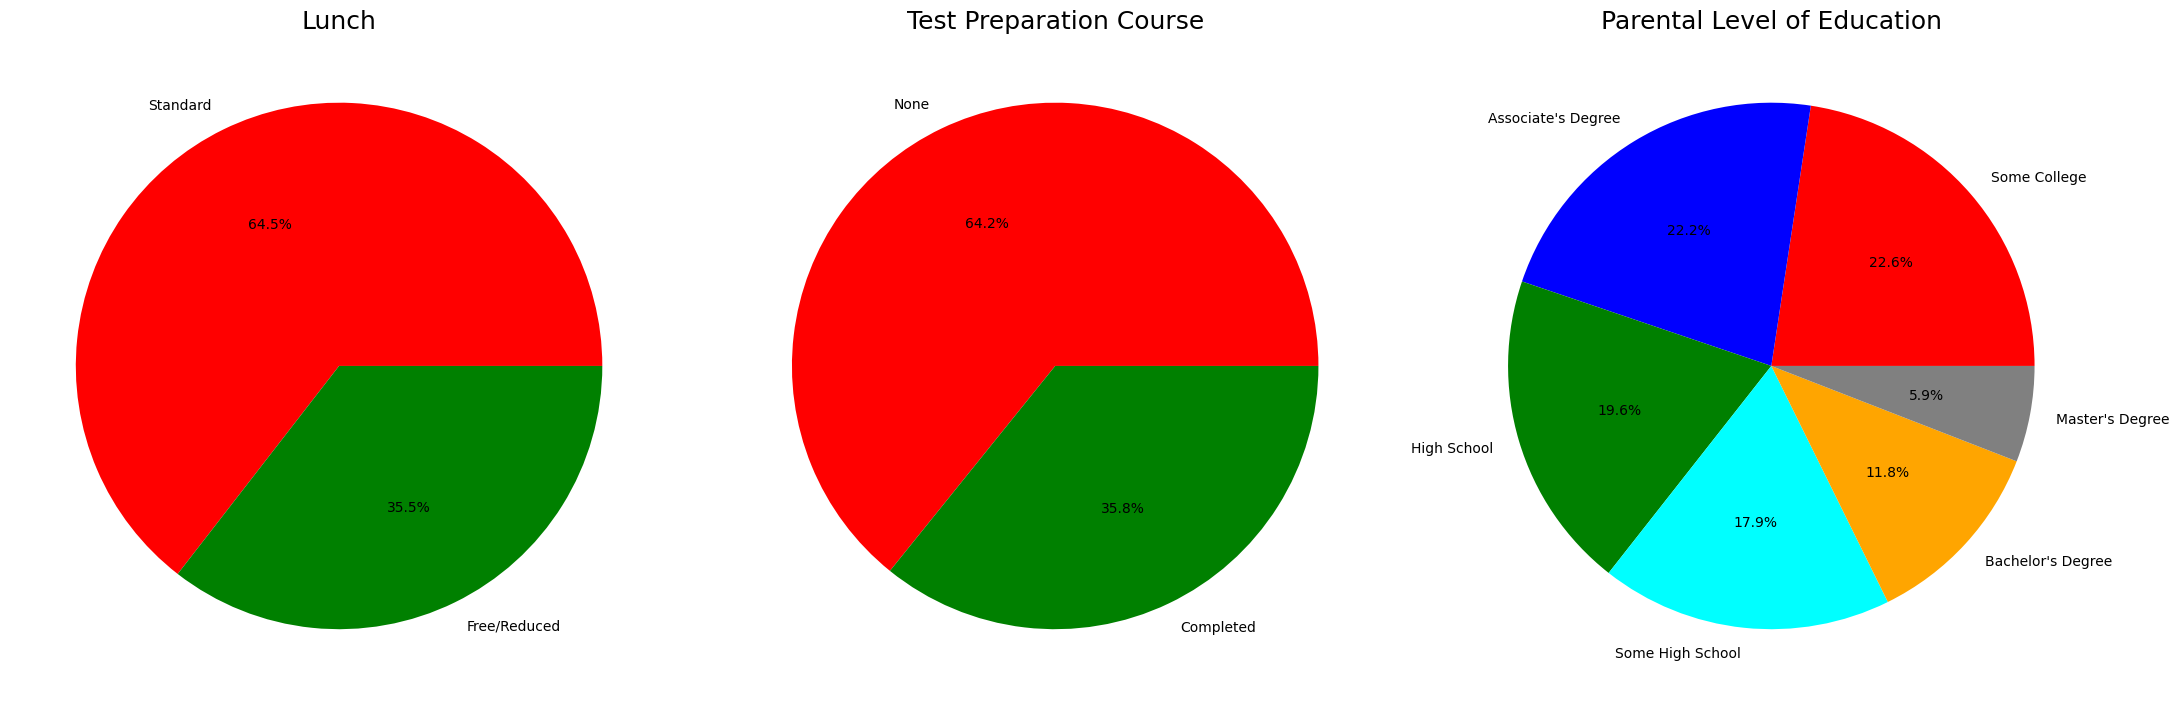

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 8))

# ---------------- Pie 1: Lunch ----------------
plt.subplot(1, 3, 1)

size = df['lunch'].value_counts()
labels = ['Standard', 'Free/Reduced']
colors = ['red', 'green']

plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Lunch', fontsize=18)
plt.axis('off')


# ---------------- Pie 2: Test Preparation Course ----------------
plt.subplot(1, 3, 2)

size = df['test preparation course'].value_counts()
labels = ['None', 'Completed']
colors = ['red', 'green']

plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Test Preparation Course', fontsize=18)
plt.axis('off')


# ---------------- Pie 3: Parental Level of Education ----------------
plt.subplot(1, 3, 3)

size = df['parental level of education'].value_counts()
labels = [
    "Some College",
    "Associate's Degree",
    "High School",
    "Some High School",
    "Bachelor's Degree",
    "Master's Degree"
]
colors = ['red', 'blue', 'green', 'cyan', 'orange', 'grey']

plt.pie(size, colors=colors, labels=labels, autopct='%2.1f%%')
plt.title('Parental Level of Education', fontsize=18)
plt.axis('off')

plt.tight_layout()
plt.show()


In [16]:
race_count = df['race/ethnicity'].value_counts()
print(race_count)


race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64


In [18]:
test_prep_count = df['test preparation course'].value_counts()
print(test_prep_count)


test preparation course
none         642
completed    358
Name: count, dtype: int64


In [17]:
lunch_count = df['lunch'].value_counts()
print(lunch_count)


lunch
standard        645
free/reduced    355
Name: count, dtype: int64
